# Prepare the Augmenterra delivery

Turns the Augmenterra SqueeSAR delivery (one folder of shapefiles per orbit direction) into the GeoParquet file
that `aducat_val.readers.augmenterra` reads, and adds velocities fitted over fixed periods so that they can be
compared with the other datasets.

| | |
|---|---|
| **Input** | `INPUT_DIR/*.shp` (e.g. `…/Augmenterra/ASC`): points in EPSG:4326, attributes + displacement time series `D<YYYYMMDD>` [mm] |
| **Output** | `OUTPUT_FILE` (e.g. `…/Augmenterra/processed/VIENNA_TUNNELLING_velocity_ASC.parquet`): all input columns plus `VEL_<start>_<end>` and `V_STDERR_<start>_<end>` per period in `INTERVALS` |
| **Optional output** | the same file split into `…_without_timeseries.parquet` (all attributes) and `…_just_timeseries.parquet` (`CODE` + time series) |

**Workflow**
1. Inspect the delivery: file list and schema from the shapefile headers, a small sample of points, one time series.
2. Check the velocity fit on the sample against the provider velocity `VEL`.
3. Process all shapefiles in chunks and write the parquet file (only if `RUN_PROCESSING = True`).
4. Optionally split the result into an attribute file and a time-series file.
5. Check the output file.

**Velocity per period**: ordinary least-squares line through the displacements of the period
(`aducat_val.timeseries.linear_fit`); the slope is the velocity [mm/yr], its standard error comes from the
residuals (same as `np.polyfit(..., cov=True)`). Dates without a value are skipped point by point; points with fewer
than `MIN_OBSERVATIONS` values in the period get NaN. Over the whole delivery period the fit reproduces
Augmenterra's own `VEL` (section 2), so the periods are computed the same way as the provider velocity.

Conventions: `docs/conventions.md` (LOS, mm and mm/yr, negative = away from the satellite).

In [1]:

import shutil
import sys
import time
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyogrio
from IPython.display import display

try:
    import aducat_val
except ImportError:  # package not installed with `pip install -e .`: use src/ of this repo (see README.md)
    repo_root = next(p for p in Path.cwd().resolve().parents if (p / "src" / "aducat_val").is_dir())
    sys.path.insert(0, str(repo_root / "src"))

from aducat_val import metrics, readers
from aducat_val import timeseries as tsa
from aducat_val.display import show


## Configuration

The processing step (section 3) reads all shapefiles (~6 GB per orbit direction) and **overwrites** the output file,
so it only runs with `RUN_PROCESSING = True`. Sections 1, 2 and 5 only read and are always safe to run.

In [ ]:

ORBIT_DIRECTION = "ASC"                     # "ASC" or "DSC"

# ---- Paths: set them to where the data is on your machine ----
INPUT_DIR = Path(f"/home/lukas/projects/ADUCAT/data/Augmenterra/{ORBIT_DIRECTION}")      # the shapefiles
OUTPUT_DIR = Path("/home/lukas/projects/ADUCAT/data/Augmenterra/processed")
OUTPUT_FILE = OUTPUT_DIR / f"VIENNA_TUNNELLING_velocity_{ORBIT_DIRECTION}.parquet"

# Periods (start, end), both inclusive, for which a velocity is fitted -> columns VEL_<start>_<end>, V_STDERR_<start>_<end>
INTERVALS = [
    ("2022-01-01", "2024-12-31"),           # common comparison period (docs/conventions.md)
    ("2020-01-01", "2024-12-31"),           # EGMS period
    ("2019-01-01", "2026-04-30"),           # whole delivery
]
MIN_OBSERVATIONS = 3                        # fewer valid dates in a period -> NaN
ROUND_DECIMALS = 1                          # decimals of the fitted columns (provider VEL has 1); None = no rounding

# Processing (section 3)
RUN_PROCESSING = False                      # True: (re)create OUTPUT_FILE from the shapefiles
WRITE_SPLIT_FILES = True                    # True: also write the attribute-only and time-series-only files
CHUNK_SIZE = 50_000                         # points read at once (~150 MB per 50k points)
MAX_SHAPEFILES = None                       # for testing: only the first n shapefiles; None = all

# Inspection (sections 1 and 2)
SAMPLE_SIZE = 5_000                         # points read from the first shapefile
INSPECT_CODE = None                         # CODE of the point to plot in section 1.3; None = first point of the sample

TS_PATTERN = r"D(\d{8})"                    # time-series columns D<YYYYMMDD>


## 1. Inspect the delivery

### 1.1 Files

From the shapefile headers only (no point data read).

In [3]:

shapefiles = sorted(INPUT_DIR.glob("*.shp"))
if not shapefiles:
    raise FileNotFoundError(f"No shapefiles in {INPUT_DIR}")
if MAX_SHAPEFILES:
    shapefiles = shapefiles[:MAX_SHAPEFILES]

infos = {shp.name: pyogrio.read_info(shp) for shp in shapefiles}
file_table = pd.DataFrame({
    name: {
        "points": info["features"],
        "fields": len(info["fields"]),
        "geometry": info["geometry_type"],
        "CRS": info["crs"],
        "size [MB]": shp.with_suffix(".dbf").stat().st_size / 1e6,
    }
    for (name, info), shp in zip(infos.items(), shapefiles)
}).T
display(file_table)

TOTAL_POINTS = int(file_table["points"].sum())
print(f"{len(shapefiles)} shapefiles, {TOTAL_POINTS:,} points in total")

# All files must have the same fields in the same order, otherwise they cannot go into one parquet file
fields = [tuple(info["fields"]) for info in infos.values()]
if len(set(fields)) != 1:
    raise ValueError("The shapefiles have different fields: check the delivery")


,points,fields,geometry,CRS,size [MB]
AT_VIENNA_TUNNELLING_SNT_T73_A_1_ES13437A001S.shp,19922,358,Point,EPSG:4326,43.082854
AT_VIENNA_TUNNELLING_SNT_T73_A_2_ES13437A001S.shp,13176,358,Point,EPSG:4326,28.498002
AT_VIENNA_TUNNELLING_SNT_T73_A_3_ES13437A001S.shp,376809,358,Point,EPSG:4326,814.672548
AT_VIENNA_TUNNELLING_SNT_T73_A_4_ES13437A001S.shp,71031,358,Point,EPSG:4326,153.580512
AT_VIENNA_TUNNELLING_SNT_T73_A_5_ES13437A001S.shp,289743,358,Point,EPSG:4326,626.435856
AT_VIENNA_TUNNELLING_SNT_T73_A_6_ES13437A001S.shp,694879,358,Point,EPSG:4326,1502.339888
AT_VIENNA_TUNNELLING_SNT_T73_A_7_ES13437A001S.shp,306695,358,Point,EPSG:4326,663.08608
AT_VIENNA_TUNNELLING_SNT_T73_A_8_ES13437A001S.shp,284632,358,Point,EPSG:4326,615.385874
AT_VIENNA_TUNNELLING_SNT_T73_A_9_ES13437A001S.shp,868039,358,Point,EPSG:4326,1876.711808


9 shapefiles, 2,924,926 points in total


### 1.2 Columns

A sample of `SAMPLE_SIZE` points of the first shapefile. Time-series columns are summarised separately.

In [4]:

sample = pyogrio.read_dataframe(shapefiles[0], max_features=SAMPLE_SIZE)
ts_cols = readers.ts_columns(sample.columns, TS_PATTERN)
dates = pd.DatetimeIndex(list(ts_cols.values()))
attribute_cols = [c for c in sample.columns if c not in ts_cols and c != "geometry"]

print(f"Sample: {len(sample):,} points, CRS {sample.crs.to_string()}")
print(f"Time series: {len(dates)} dates, {dates.min().date()} – {dates.max().date()}, "
      f"median spacing {dates.to_series().diff().dt.days.median():.0f} days, "
      f"time-series values: {sample[list(ts_cols)].isna().mean().mean():.1%} NaN")
print(f"Attribute columns ({len(attribute_cols)}):")
display(sample[attribute_cols].describe(include="all").T)


Sample: 5,000 points, CRS EPSG:4326
Time series: 343 dates, 2019-01-05 – 2026-04-28, median spacing 6 days, time-series values: 0.0% NaN
Attribute columns (15):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CODE,5000,5000,CW0WJE401,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HEIGHT,5000.0,NaN,NaN,NaN,206.53212,8.538173,180.6,200.9,208.0,211.8,238.2
H_STDEV,5000.0,NaN,NaN,NaN,2.27708,0.30834,1.4,2.1,2.3,2.5,3.1
VEL,5000.0,NaN,NaN,NaN,-0.4077,1.259679,-5.0,-1.1,-0.3,0.3,3.0
V_STDEV,5000.0,NaN,NaN,NaN,0.18568,0.035031,0.1,0.2,0.2,0.2,0.2
ACC,5000.0,NaN,NaN,NaN,0.01602,0.359749,-1.6,-0.2,0.0,0.2,1.5
A_STDEV,5000.0,NaN,NaN,NaN,0.19296,0.026955,0.1,0.2,0.2,0.2,0.3
SEASON_AMP,5000.0,NaN,NaN,NaN,0.978438,0.608554,0.01,0.56,0.88,1.27,6.07
S_AMP_STD,5000.0,NaN,NaN,NaN,0.564002,0.074992,0.34,0.52,0.58,0.62,0.76
SEASON_PHS,5000.0,NaN,NaN,NaN,16.30979,101.985986,-182.24,-57.275,13.57,105.0,182.5


### 1.3 One time series

With the fitted line of every period in `INTERVALS`.

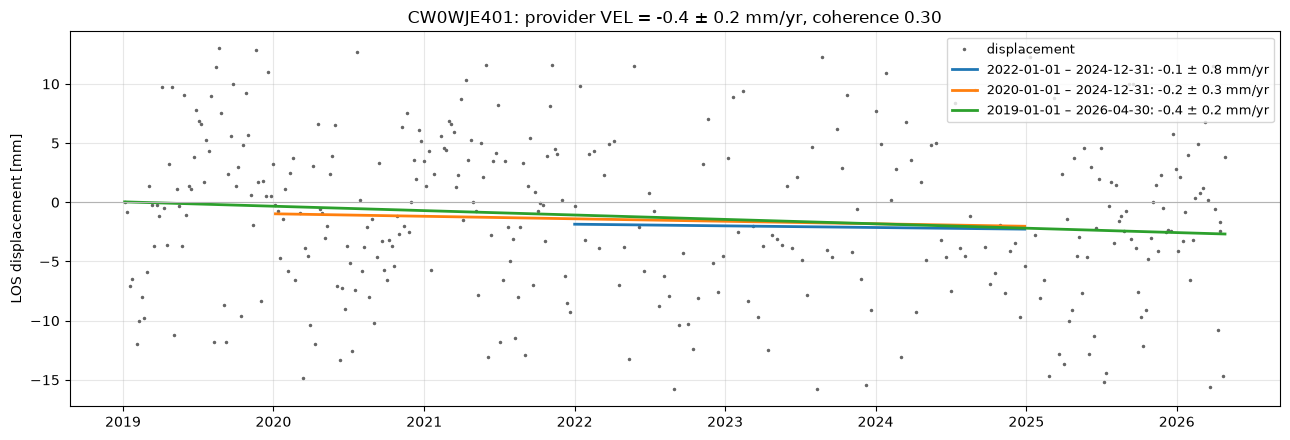

In [5]:

point = sample.iloc[0] if INSPECT_CODE is None else sample.loc[sample["CODE"] == INSPECT_CODE].iloc[0]
series = pd.Series(point[list(ts_cols)].to_numpy(dtype=float), index=dates)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(series.index, series.to_numpy(), ".", ms=3, color="0.4", label="displacement")
for k, (start, end) in enumerate(INTERVALS):
    part = series[start:end]
    rate, rate_std = tsa.linear_fit(part.to_numpy()[None, :], part.index, MIN_OBSERVATIONS)
    years = tsa.decimal_years(part.index)
    offset = np.nanmean(part.to_numpy() - rate[0] * years)
    ax.plot(part.index, offset + rate[0] * years, color=f"C{k}", lw=2,
            label=f"{start} – {end}: {rate[0]:.1f} ± {rate_std[0]:.1f} mm/yr")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_ylabel("LOS displacement [mm]")
ax.set_title(f"{point['CODE']}: provider VEL = {point['VEL']:.1f} ± {point['V_STDEV']:.1f} mm/yr, "
             f"coherence {point['COHERENCE']:.2f}")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


## 2. Velocity fit

`add_period_velocities` adds the fitted columns to a table of points. It is used on the sample here and on every
chunk in section 3.

The fit over the whole delivery period is compared with the provider velocity `VEL`, which is a linear fit over the
same period: they should agree to the rounding (0.1 mm/yr). A larger difference points to a unit, sign or date problem.

In [6]:

def add_period_velocities(points, intervals=INTERVALS, min_observations=MIN_OBSERVATIONS, decimals=ROUND_DECIMALS):
    """Add VEL_<start>_<end> and V_STDERR_<start>_<end> [mm/yr] for every period to a table with D<YYYYMMDD> columns.

    Returns the same table (modified in place). Periods with fewer than min_observations dates are skipped.
    """
    cols = readers.ts_columns(points.columns, TS_PATTERN)
    for start, end in intervals:
        in_period = [c for c, d in cols.items() if pd.Timestamp(start) <= d <= pd.Timestamp(end)]
        if len(in_period) < min_observations:
            print(f"Skipped {start} – {end}: only {len(in_period)} dates")
            continue
        rate, rate_std = tsa.linear_fit(points[in_period].to_numpy(dtype=np.float64),
                                        [cols[c] for c in in_period], min_observations)
        if decimals is not None:
            rate, rate_std = np.round(rate, decimals), np.round(rate_std, decimals)
        suffix = f"{pd.Timestamp(start):%Y%m%d}_{pd.Timestamp(end):%Y%m%d}"
        points[f"VEL_{suffix}"] = rate
        points[f"V_STDERR_{suffix}"] = rate_std
    return points


sample = add_period_velocities(sample)
velocity_cols = [c for c in sample.columns if c.startswith("VEL_")]

show(pd.DataFrame({c: metrics.velocity_summary(sample[c]) for c in ["VEL", *velocity_cols]}))
full_period = velocity_cols[-1]
print(f"Fit over the whole period ({full_period}) − provider VEL:")
show(pd.Series(metrics.difference_metrics(sample["VEL"], sample[full_period])).to_frame("sample"))


,VEL,VEL_20220101_20241231,VEL_20200101_20241231,VEL_20190101_20260430
points,"5,000","5,000","5,000","5,000"
mean,-0.41,-0.45,-0.40,-0.41
std,1.26,1.75,1.38,1.26
min,-5.00,-8.80,-6.80,-5.00
P2,-3.80,-4.60,-4.00,-3.90
P25,-1.10,-1.50,-1.10,-1.10
median,-0.30,-0.40,-0.30,-0.30
P75,0.30,0.60,0.40,0.30
P98,2.00,3.00,2.40,2.00
max,3.00,6.40,4.20,3.00


Fit over the whole period (VEL_20190101_20260430) − provider VEL:


,sample
N,"5,000"
bias [mm/yr],-0.00
median diff. [mm/yr],0.00
MAE [mm/yr],0.00
RMSE [mm/yr],0.01
std diff. [mm/yr],0.01
NMAD [mm/yr],0.00
|diff| ≤ 2 mm/yr [%],100.00
Pearson r,1.00
Spearman ρ,1.00


## 3. Process all shapefiles

Every shapefile is read in chunks of `CHUNK_SIZE` points; the fitted columns are added and each chunk is written to a
temporary parquet file. The chunks are then combined into one file. The result is first written under a temporary
name and only renamed to `OUTPUT_FILE` at the end, so an interrupted run does not destroy an existing file.
Runtime: a few minutes per orbit direction (dominated by reading the shapefiles).

In [7]:

def write_chunks(shapefiles, parts_dir):
    """Read all shapefiles chunk by chunk, add the period velocities, write one parquet file per chunk.

    Returns (list of chunk files, total bounds (minx, miny, maxx, maxy) of all points).
    """
    parts, bounds = [], [np.inf, np.inf, -np.inf, -np.inf]
    for k, shp in enumerate(shapefiles, start=1):
        n_points = infos[shp.name]["features"]
        t0 = time.perf_counter()
        for start in range(0, n_points, CHUNK_SIZE):
            chunk = pyogrio.read_dataframe(shp, skip_features=start, max_features=CHUNK_SIZE)
            chunk = add_period_velocities(chunk)
            part = parts_dir / f"part_{len(parts):05d}.parquet"
            chunk.to_parquet(part, index=False, compression="zstd")
            parts.append(part)
            x0, y0, x1, y1 = chunk.total_bounds
            bounds = [min(bounds[0], x0), min(bounds[1], y0), max(bounds[2], x1), max(bounds[3], y1)]
        print(f"{k}/{len(shapefiles)} {shp.name}: {n_points:,} points in {time.perf_counter() - t0:.0f} s")
    return parts, bounds


def combine_parts(parts, bounds, target):
    """Concatenate the chunk files into ``target``; the GeoParquet bbox is set to the bounds of all points."""
    schema = pq.read_schema(parts[0])
    geo = json.loads(schema.metadata[b"geo"])
    geo["columns"]["geometry"]["bbox"] = [float(b) for b in bounds]
    schema = schema.with_metadata({**schema.metadata, b"geo": json.dumps(geo).encode()})
    with pq.ParquetWriter(target, schema, compression="zstd") as writer:
        for part in parts:
            writer.write_table(pq.read_table(part).cast(schema))


if RUN_PROCESSING:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    parts_dir = OUTPUT_DIR / f".{OUTPUT_FILE.stem}_parts"
    tmp_file = OUTPUT_FILE.with_name(OUTPUT_FILE.name + ".tmp")
    parts_dir.mkdir(exist_ok=True)
    try:
        t0 = time.perf_counter()
        parts, bounds = write_chunks(shapefiles, parts_dir)
        combine_parts(parts, bounds, tmp_file)
        tmp_file.replace(OUTPUT_FILE)
        print(f"Written {OUTPUT_FILE} ({OUTPUT_FILE.stat().st_size / 1e9:.2f} GB) in {time.perf_counter() - t0:.0f} s")
    finally:
        shutil.rmtree(parts_dir, ignore_errors=True)
        tmp_file.unlink(missing_ok=True)
else:
    print(f"RUN_PROCESSING is False: {OUTPUT_FILE.name} is not rewritten")


RUN_PROCESSING is False: VIENNA_TUNNELLING_velocity_ASC.parquet is not rewritten


## 4. Split into an attribute file and a time-series file (optional)

Smaller files for tools that cannot read only some columns (e.g. QGIS): `…_without_timeseries.parquet` has every
column except the time series, `…_just_timeseries.parquet` has `CODE` and the time series. The validation notebooks
use the full file.

In [8]:

def copy_columns(source, target, columns, keep_geo):
    """Write the given columns of a parquet file to a new file, batch by batch."""
    pf = pq.ParquetFile(source)
    metadata = dict(pf.schema_arrow.metadata or {})
    if not keep_geo:
        metadata.pop(b"geo", None)
    schema = pa.schema([pf.schema_arrow.field(c) for c in columns], metadata=metadata)
    with pq.ParquetWriter(target, schema, compression="zstd") as writer:
        for batch in pf.iter_batches(batch_size=CHUNK_SIZE, columns=columns):
            writer.write_table(pa.Table.from_batches([batch]).cast(schema))


if RUN_PROCESSING and WRITE_SPLIT_FILES:
    all_columns = pq.read_schema(OUTPUT_FILE).names
    file_ts_cols = list(readers.ts_columns(all_columns, TS_PATTERN))
    split = {
        OUTPUT_FILE.with_name(f"{OUTPUT_FILE.stem}_without_timeseries.parquet"):
            ([c for c in all_columns if c not in file_ts_cols], True),
        OUTPUT_FILE.with_name(f"{OUTPUT_FILE.stem}_just_timeseries.parquet"): (["CODE", *file_ts_cols], False),
    }
    for target, (columns, keep_geo) in split.items():
        copy_columns(OUTPUT_FILE, target, columns, keep_geo)
        print(f"Written {target.name}: {len(columns)} columns, {target.stat().st_size / 1e9:.2f} GB")
else:
    print("Split files not written (RUN_PROCESSING or WRITE_SPLIT_FILES is False)")


Split files not written (RUN_PROCESSING or WRITE_SPLIT_FILES is False)


## 5. Check the output file

The file must contain every point of the delivery and the fitted columns, and `aducat_val.readers` must be able to
read it. Only the footer and the velocity columns are read.

In [9]:

src = readers.augmenterra(OUTPUT_FILE)
pf = pq.ParquetFile(src.file)
names = pf.schema_arrow.names
expected = [f"{p}_{pd.Timestamp(s):%Y%m%d}_{pd.Timestamp(e):%Y%m%d}" for s, e in INTERVALS for p in ("VEL", "V_STDERR")]

checks = {
    "points in file": f"{pf.metadata.num_rows:,}",
    "points in shapefiles": f"{TOTAL_POINTS:,}" + ("" if MAX_SHAPEFILES is None else f" (first {MAX_SHAPEFILES} files)"),
    "same number of points": pf.metadata.num_rows == TOTAL_POINTS,
    "all fitted columns present": all(c in names for c in expected),
    "geometry CRS": readers.parquet_crs(pf).to_string(),
}
display(pd.Series(checks).to_frame(src.file.name))
display(pd.DataFrame(readers.file_overview(src), index=["value"]).T)

fitted = pq.read_table(src.file, columns=["VEL", *[c for c in expected if c.startswith("VEL_") and c in names]]).to_pandas()
show(pd.DataFrame({c: metrics.velocity_summary(fitted[c]) for c in fitted}))


,VIENNA_TUNNELLING_velocity_ASC.parquet
points in file,"2,924,926"
points in shapefiles,"2,924,926"
same number of points,True
all fitted columns present,True
geometry CRS,EPSG:4326


,value
file,VIENNA_TUNNELLING_velocity_ASC.parquet
size [GB],1.44
points,"2,924,926"
row groups,150
geometry CRS,EPSG:4326
time steps,343
first date,2019-01-05
last date,2026-04-28
median spacing [days],6.0
velocity column,VEL_20220101_20241231


,VEL,VEL_20220101_20241231,VEL_20200101_20241231,VEL_20190101_20260430
points,"2,924,926","2,924,926","2,924,926","2,924,926"
mean,-0.21,-0.34,-0.25,-0.21
std,1.36,1.75,1.48,1.36
min,-23.10,-25.30,-23.90,-23.10
P2,-4.10,-5.00,-4.50,-4.10
P25,-0.60,-1.00,-0.70,-0.60
median,-0.00,-0.20,-0.10,0.00
P75,0.40,0.50,0.40,0.40
P98,2.30,3.10,2.50,2.30
max,14.50,14.10,14.40,14.50
